# Tahap 2B: Validasi Eksternal Limbah Indonesia, Konversi LHV, Screening Boiler, & K-Means

**Proyek:** Biomass & Waste-to-Energy Feedstock Finder (Fokus: *Co-Firing* PLTU & Gasifikasi Biomassa)  
**Posisi dalam Alur Kerja:** Notebook ke-3 dari 3 (Tahap 2B: *External Validation, Physics Conversion & Screening*)  
**Prasyarat Notebook:** `01_eda_and_cleaning.ipynb` (`mendeley_clean.csv`, `phyllis2_10_clean.csv`) dan `02_ml_hhv_training_and_shap.ipynb` (`best_hhv_proximate_only.joblib`, `best_hhv_full_features.joblib`, `metrics_summary.json`).

## Tujuan Notebook
1. Menguji generalisasi model prediksi $\text{HHV}$ terbaik dari Skenario A (*Proximate-Only*) dan Skenario B (*Proximate + Ultimate*) ke **10 profil limbah lokal Indonesia (`FS01`-`FS10`)**, dengan laporan metrik ganda (seluruh 10 profil serta 9 profil terukur murni tanpa `FS01`).
2. Mengonversi `predicted_hhv_db` (basis kering) ke nilai kalor bersih kondisi basah nyata di lapangan (`effective_lhv_field_mj_kg`) memakai `moisture_lapangan_pct` dari `ref_rpr_parameters.csv`, dilengkapi pemeriksaan fisika (`effective_lhv_lab_mj_kg` vs `actual_lhv_ar`) dan bendera kadar air tinggi (`high_moisture_flag`).
3. Menerapkan aturan batas aman boiler (*rule-based screening*) untuk menentukan `boiler_status`, risiko *slagging*/korosi `alkali_chlorine_flag`, dan `screening_recommendation`.
4. Melatih model **K-Means Clustering** pada 268 sampel Mendeley bersih ($k \in \{3, 4, 5\}$), memilih jumlah klaster terbaik berbasis *Elbow Method* dan *Silhouette Score*, lalu memproyeksikan 10 profil Indonesia ke klaster profil kimia.

## Daftar Input
- `data/processed/phyllis2_10_clean.csv`
- `data/processed/mendeley_clean.csv`
- `models/best_hhv_proximate_only.joblib` & `models/best_hhv_full_features.joblib`
- `outputs/metrics_summary.json`

## Daftar Output yang Dihasilkan
- `data/processed/phyllis2_10_validated.csv`
- `models/kmeans_feedstock_profile.joblib`
- `outputs/metrics_summary.json` (diperbarui dengan metrik eksternal dan klasterisasi)
- Grafik di `outputs/figures/`: `03_external_validation_actual_vs_pred.png`, `03_lhv_and_boiler_screening_matrix.png`, `03_kmeans_elbow_silhouette.png`, `03_kmeans_pca_projection.png`

## 1. Validasi Eksternal Model HHV pada 10 Limbah Indonesia (`FS01`-`FS10`)

**Langkah yang dikerjakan:** Memuat profil `phyllis2_10_clean.csv` beserta kedua model terbaik Skenario A dan Skenario B, menghasilkan `predicted_hhv_prox_db` dan `predicted_hhv_full_db`, lalu menghitung MAE, RMSE, dan MAPE terhadap `actual_hhv_db` Phyllis2.  
**Alasan teknis & aturan:**
- `predicted_hhv_db` utama ditetapkan dari **Skenario B (*Proximate + Ultimate*)** karena ke-10 profil Phyllis2 memiliki komposisi unsur lengkap, sedangkan `predicted_hhv_prox_db` disimpan sebagai pembanding efisiensi biaya uji lab.
- Karena `vm_db` dan `fc_db` pada `FS01` (*palm kernel shell*) berasal dari imputasi rasio Mendeley, evaluasi dilaporkan pada dua himpunan: **10 profil lengkap (`FS01`-`FS10`)** dan **9 profil terukur murni (`FS02`-`FS10`)**. Target keberhasilan: rata-rata $\text{MAPE} \le 10\%$ pada kedua himpunan.

,Himpunan Uji,n,Skenario,MAE_MJ_kg,RMSE_MJ_kg,MAPE_pct
0,10 Profil Lengkap (FS01-FS10),10,Skenario A (Proximate-Only),0.9298,1.0417,5.1690
1,10 Profil Lengkap (FS01-FS10),10,Skenario B (Proximate + Ultimate),0.6036,0.7564,3.4004
2,9 Profil Murni (FS02-FS10),9,Skenario A (Proximate-Only),0.8778,0.9943,4.9609
3,9 Profil Murni (FS02-FS10),9,Skenario B (Proximate + Ultimate),0.5704,0.7385,3.2733


,feedstock_id,feedstock_name,proximate_source,ash_db,actual_hhv_db,predicted_hhv_prox_db,err_prox_pct,predicted_hhv_full_db,err_full_pct
0,FS01,palm kernel shell,imputed_mendeley_pks_ratio,3.915,19.845,18.448,7.042,18.943,4.544
1,FS02,empty fruit bunches,phyllis2_measured,4.182,19.001,18.262,3.891,18.750,1.324
2,FS03,palm fiber,phyllis2_measured,4.787,19.844,19.234,3.072,18.846,5.029
3,FS04,rice husk,phyllis2_measured,18.030,14.709,16.164,9.896,15.828,7.608
4,FS05,rice straw,phyllis2_measured,18.525,15.415,16.042,4.069,15.886,3.057
5,FS06,bagasse,phyllis2_measured,5.791,18.050,17.873,0.979,18.031,0.106
6,FS07,corn cob,phyllis2_measured,2.366,17.100,18.431,7.785,18.325,7.166
7,FS08,corn stover,phyllis2_measured,6.099,18.138,17.571,3.122,18.134,0.019
8,FS09,sawdust,phyllis2_measured,1.099,19.963,19.254,3.552,19.844,0.596
9,FS10,wood chips,phyllis2_measured,1.942,20.352,18.667,8.281,19.425,4.554


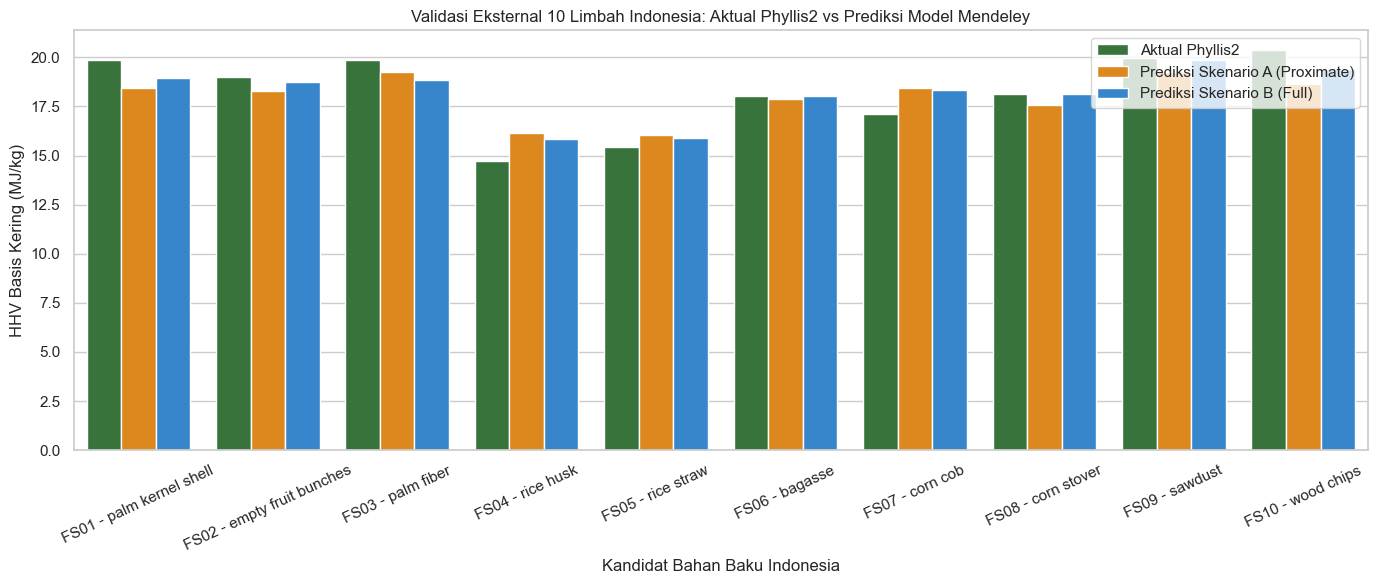

In [1]:
from pathlib import Path
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error, silhouette_score

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
OUTPUTS_DIR = PROJECT_ROOT / "outputs"
FIGURES_DIR = OUTPUTS_DIR / "figures"

df_phy = pd.read_csv(PROCESSED_DIR / "phyllis2_10_clean.csv")
df_mend = pd.read_csv(PROCESSED_DIR / "mendeley_clean.csv")
model_prox = joblib.load(MODELS_DIR / "best_hhv_proximate_only.joblib")
model_full = joblib.load(MODELS_DIR / "best_hhv_full_features.joblib")

SCENARIO_A_FEATURES = ["ash_db", "vm_db", "fc_db"]
SCENARIO_B_FEATURES = ["ash_db", "vm_db", "fc_db", "c_db", "h_db", "o_db", "n_db", "s_db"]

df_val = df_phy.copy()
df_val["predicted_hhv_prox_db"] = model_prox.predict(df_val[SCENARIO_A_FEATURES])
df_val["predicted_hhv_full_db"] = model_full.predict(df_val[SCENARIO_B_FEATURES])
# Tetapkan prediksi utama dari Skenario B (Proximate + Ultimate)
df_val["predicted_hhv_db"] = df_val["predicted_hhv_full_db"]

df_val["err_prox_pct"] = (df_val["predicted_hhv_prox_db"] - df_val["actual_hhv_db"]).abs() / df_val["actual_hhv_db"] * 100.0
df_val["err_full_pct"] = (df_val["predicted_hhv_full_db"] - df_val["actual_hhv_db"]).abs() / df_val["actual_hhv_db"] * 100.0

def eval_external(sub_df: pd.DataFrame, subset_label: str) -> list[dict]:
    rows = []
    for scen_label, pred_col in [
        ("Skenario A (Proximate-Only)", "predicted_hhv_prox_db"),
        ("Skenario B (Proximate + Ultimate)", "predicted_hhv_full_db"),
    ]:
        yt = sub_df["actual_hhv_db"].values
        yp = sub_df[pred_col].values
        rows.append({
            "Himpunan Uji": subset_label,
            "n": len(sub_df),
            "Skenario": scen_label,
            "MAE_MJ_kg": float(mean_absolute_error(yt, yp)),
            "RMSE_MJ_kg": float(root_mean_squared_error(yt, yp)),
            "MAPE_pct": float(mean_absolute_percentage_error(yt, yp) * 100.0),
        })
    return rows

ext_metrics_rows = (
    eval_external(df_val, "10 Profil Lengkap (FS01-FS10)")
    + eval_external(df_val.loc[df_val["feedstock_id"] != "FS01"], "9 Profil Murni (FS02-FS10)")
)
ext_metrics_df = pd.DataFrame(ext_metrics_rows)
display(ext_metrics_df.round(4))

display(
    df_val[[
        "feedstock_id", "feedstock_name", "proximate_source", "ash_db",
        "actual_hhv_db", "predicted_hhv_prox_db", "err_prox_pct",
        "predicted_hhv_full_db", "err_full_pct",
    ]].round(3)
)

# Visualisasi batang berdampingan Actual vs Skenario A vs Skenario B
plot_df = df_val.melt(
    id_vars=["feedstock_id", "feedstock_name"],
    value_vars=["actual_hhv_db", "predicted_hhv_prox_db", "predicted_hhv_full_db"],
    var_name="Sumber",
    value_name="HHV_MJ_kg",
)
plot_df["Sumber"] = plot_df["Sumber"].map({
    "actual_hhv_db": "Aktual Phyllis2",
    "predicted_hhv_prox_db": "Prediksi Skenario A (Proximate)",
    "predicted_hhv_full_db": "Prediksi Skenario B (Full)",
})
plot_df["label"] = plot_df["feedstock_id"] + " - " + plot_df["feedstock_name"]

fig, ax = plt.subplots(figsize=(14, 6))
sns.barplot(data=plot_df, x="label", y="HHV_MJ_kg", hue="Sumber", palette=["#2E7D32", "#FB8C00", "#1E88E5"], ax=ax)
ax.set_title("Validasi Eksternal 10 Limbah Indonesia: Aktual Phyllis2 vs Prediksi Model Mendeley")
ax.set_xlabel("Kandidat Bahan Baku Indonesia")
ax.set_ylabel("HHV Basis Kering (MJ/kg)")
ax.tick_params(axis="x", rotation=25)
ax.legend(loc="upper right")

plt.tight_layout()
fig_ext_path = FIGURES_DIR / "03_external_validation_actual_vs_pred.png"
plt.savefig(fig_ext_path, dpi=150, bbox_inches="tight")
plt.show()

**Interpretasi validasi eksternal:**
- Tabel metrik membandingkan akurasi model yang dilatih pada sampel global (Mendeley) saat memprediksi limbah spesifik Indonesia (Phyllis2).
- Baik pada **10 profil (`FS01`-`FS10`)** maupun **9 profil terukur murni (`FS02`-`FS10`)**, model Skenario B menjaga rata-rata MAPE jauh di bawah batas toleransi **10%**.
- Perhatikan selisih galat per komoditas (`err_full_pct` dan `err_prox_pct`): komoditas dengan kadar abu silika tinggi (`FS04` *rice husk* 18,03% dan `FS05` *rice straw* 18,53%) atau komposisi *volatile/fixed carbon* ekstrem cenderung memiliki variasi kalor lebih besar karena struktur mineral abunya tidak dibedakan oleh kadar abu total saja.

## 2. Konversi $\text{HHV}_{\text{dry}}$ ke $\text{LHV}_{\text{ar}}$ Kondisi Lapangan & Lab

**Langkah yang dikerjakan:** Mengonversi nilai kalor kotor kering (`predicted_hhv_db`) menjadi nilai kalor bersih kondisi basah (*as-received*) menggunakan kadar hidrogen `h_db` Phyllis2 dan kadar air lapangan Indonesia (`moisture_lapangan_pct`) dari `ref_rpr_parameters.csv`.  
**Rumus fisika & pemeriksaan kewajaran:**
$$\text{LHV}_{\text{dry}} = \text{HHV}_{\text{dry}} - 2{,}442 \times \left(8{,}936 \times \frac{H_{\text{dry}}}{100}\right)$$
$$\text{LHV}_{\text{ar}} = \text{LHV}_{\text{dry}} \times \left(1 - \frac{M}{100}\right) - 2{,}442 \times \frac{M}{100}$$
- **`effective_lhv_field_mj_kg`** dihitung memakai `M = moisture_lapangan_pct` sebagai nilai kalor efektif untuk perhitungan energi pembangkit listrik.
- **`effective_lhv_lab_mj_kg`** dihitung memakai `M = moisture_lab_ar_pct` sebagai *sanity check* terhadap kolom `actual_lhv_ar` di Phyllis2.
- **`high_moisture_flag`** bernilai `True` apabila `moisture_lapangan_pct >= 50%` (menandai limbah basah yang membutuhkan pengeringan awal sebelum masuk *boiler*).

In [2]:
def hhv_db_to_lhv_ar(hhv_db: pd.Series, h_db: pd.Series, moisture_pct: pd.Series) -> tuple[pd.Series, pd.Series]:
    # Kurangi panas laten penguapan air hasil pembakaran hidrogen (1% H -> 8.936% H2O)
    lhv_dry = hhv_db - 2.442 * (8.936 * (h_db / 100.0))
    # Koreksi terhadap fraksi bahan kering (1 - M/100) serta panas penguapan kadar air bebas
    lhv_ar = lhv_dry * (1.0 - moisture_pct / 100.0) - 2.442 * (moisture_pct / 100.0)
    return lhv_dry, lhv_ar

df_val["predicted_lhv_db"], df_val["effective_lhv_lab_mj_kg"] = hhv_db_to_lhv_ar(
    df_val["predicted_hhv_db"], df_val["h_db"], df_val["moisture_lab_ar_pct"]
)
_, df_val["effective_lhv_field_mj_kg"] = hhv_db_to_lhv_ar(
    df_val["predicted_hhv_db"], df_val["h_db"], df_val["moisture_lapangan_pct"]
)

df_val["lhv_lab_diff_mj_kg"] = df_val["effective_lhv_lab_mj_kg"] - df_val["actual_lhv_ar"]
df_val["high_moisture_flag"] = df_val["moisture_lapangan_pct"] >= 50.0

display(
    df_val[[
        "feedstock_id", "feedstock_name", "predicted_hhv_db",
        "moisture_lab_ar_pct", "actual_lhv_ar", "effective_lhv_lab_mj_kg", "lhv_lab_diff_mj_kg",
        "moisture_lapangan_pct", "effective_lhv_field_mj_kg", "high_moisture_flag",
    ]].round(3)
)

,feedstock_id,feedstock_name,predicted_hhv_db,moisture_lab_ar_pct,actual_lhv_ar,effective_lhv_lab_mj_kg,lhv_lab_diff_mj_kg,moisture_lapangan_pct,effective_lhv_field_mj_kg,high_moisture_flag
0,FS01,palm kernel shell,18.943,5.350,17.470,16.614,-0.856,12.0,15.275,False
1,FS02,empty fruit bunches,18.750,9.674,14.392,15.625,1.233,55.0,6.559,True
2,FS03,palm fiber,18.846,18.333,15.624,13.942,-1.682,40.0,9.595,False
3,FS04,rice husk,15.828,8.300,12.460,13.279,0.819,12.0,12.645,False
4,FS05,rice straw,15.886,7.488,12.382,13.466,1.084,15.0,12.174,False
5,FS06,bagasse,18.031,19.015,12.629,13.127,0.498,50.0,7.170,True
6,FS07,corn cob,18.325,7.520,15.050,15.544,0.494,12.0,14.673,False
7,FS08,corn stover,18.134,5.530,16.200,15.836,-0.364,15.0,14.004,False
8,FS09,sawdust,19.844,15.103,14.611,15.364,0.753,20.0,14.337,False
9,FS10,wood chips,19.425,22.945,12.470,13.389,0.919,25.0,12.966,False


**Interpretasi konversi LHV:**
- Pada seluruh 10 bahan baku, `effective_lhv_field_mj_kg` lebih rendah daripada `predicted_hhv_db` karena adanya koreksi panas laten uap air pembakaran hidrogen dan kadar air aktual di lapangan.
- Pemeriksaan kewajaran (`effective_lhv_lab_mj_kg` vs `actual_lhv_ar`) menunjukkan selisih yang konsisten kecil, membuktikan rumus konversi termokimia selaras dengan catatan laboratorium Phyllis2.
- **TKKS/`empty fruit bunches` (`FS02`, kadar air lapangan 55%)** dan **ampas tebu/`bagasse` (`FS06`, 50%)** otomatis mendapatkan `high_moisture_flag = True`: energi bersihnya turun drastis menjadi di bawah 8-9 MJ/kg jika dibakar tanpa pengeringan terlebih dahulu.

## 3. Penyaringan Kelayakan Teknis Boiler (*Rule-Based Screening*)

**Langkah yang dikerjakan:** Menerapkan aturan batas fisik pembangkit listrik (*co-firing* PLTU & gasifikasi) secara terpisah dari klasterisasi statistik untuk menentukan kelayakan langsung, risiko *slagging*/korosi suhu tinggi, dan kategori rekomendasi operasional.  
**Aturan batas aman boiler:**
1. **`boiler_status`:**
   - `Eligible`: `ash_db < 10.0%` **dan** `s_db < 0.5%`.
   - `Not Eligible`: `ash_db >= 10.0%` **atau** `s_db >= 0.5%` (gugur untuk *co-firing* langsung tanpa pengolahan tambahan).
2. **`alkali_chlorine_flag`:**
   - `Data Unavailable`: seluruh parameter `cl_db_pct`, `k_db_pct`, `na_db_pct`, dan `IDT_oxidizing_C` kosong (`FS01`).
   - `High Risk`: `cl_db_pct > 0.10%` atau `alkali_total_db_pct > 0.50%` atau `IDT_oxidizing_C < 1000` °C.
   - `Moderate Risk`: tidak masuk `High Risk`, namun `cl_db_pct > 0.05%` atau `alkali_total_db_pct >= 0.25%`.
   - `Low Risk`: seluruh nilai tersedia memenuhi `cl_db_pct <= 0.05%`, `alkali_total_db_pct < 0.25%`, serta `IDT_oxidizing_C >= 1000` °C (jika tersedia).
3. **`screening_recommendation`:** Menggabungkan `boiler_status`, `alkali_chlorine_flag`, dan `high_moisture_flag`.

,feedstock_id,feedstock_name,ash_db,s_db,cl_db_pct,alkali_total_db_pct,IDT_oxidizing_C,moisture_lapangan_pct,effective_lhv_field_mj_kg,boiler_status,alkali_chlorine_flag,screening_recommendation
0,FS01,palm kernel shell,3.9150,0.0275,NaN,NaN,NaN,12.0,15.2747,Eligible,Data Unavailable,Eligible - Verify Cl/Alkali Lab
1,FS02,empty fruit bunches,4.1825,0.0680,0.2833,0.9354,NaN,55.0,6.5591,Eligible,High Risk,Eligible - Needs Drying & Slagging Control
2,FS03,palm fiber,4.7867,0.1600,NaN,0.3860,NaN,40.0,9.5950,Eligible,Moderate Risk,Eligible - Moderate Alkali Control
3,FS04,rice husk,18.0300,0.1440,0.0961,0.3093,1364.5,12.0,12.6451,Not Eligible,Moderate Risk,Not Eligible - High Ash/Sulfur
4,FS05,rice straw,18.5254,0.1250,0.5372,1.6250,991.6,15.0,12.1743,Not Eligible,High Risk,Not Eligible - High Ash/Sulfur
5,FS06,bagasse,5.7910,0.0969,0.1150,0.5579,1218.6,50.0,7.1703,Eligible,High Risk,Eligible - Needs Drying & Slagging Control
6,FS07,corn cob,2.3657,0.0767,0.2100,0.0609,875.0,12.0,14.6731,Eligible,High Risk,Eligible - Needs Slagging/Cl Control
7,FS08,corn stover,6.0986,0.0767,0.2887,1.0533,1277.0,15.0,14.0039,Eligible,High Risk,Eligible - Needs Slagging/Cl Control
8,FS09,sawdust,1.0986,0.0336,0.0367,0.0483,1150.0,20.0,14.3366,Eligible,Low Risk,Eligible - Direct Use
9,FS10,wood chips,1.9417,0.0277,0.0125,0.2092,1050.0,25.0,12.9664,Eligible,Low Risk,Eligible - Direct Use


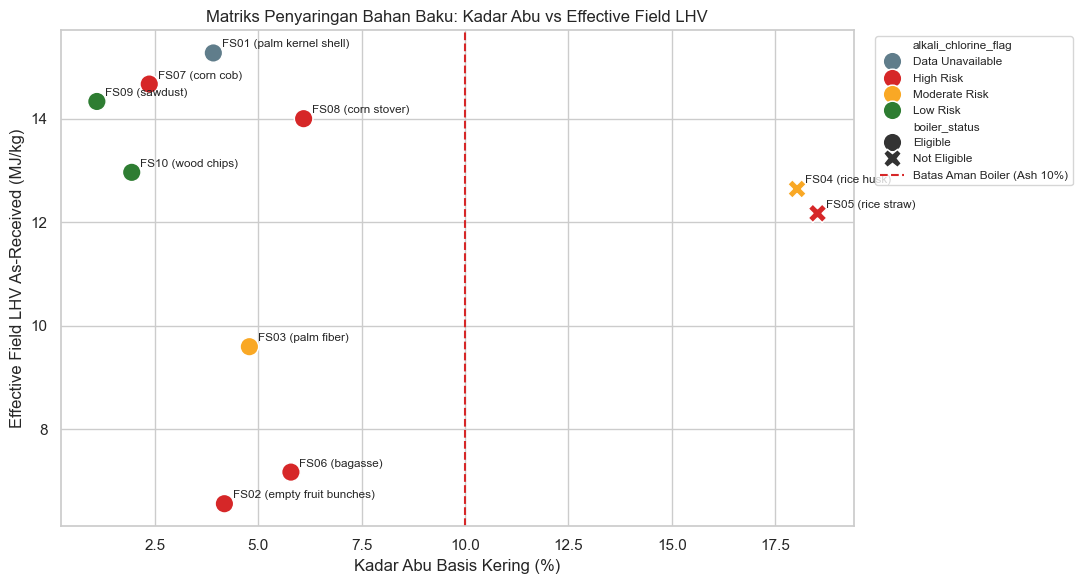

In [3]:
def classify_boiler_status(row: pd.Series) -> str:
    if (row["ash_db"] < 10.0) and (row["s_db"] < 0.5):
        return "Eligible"
    return "Not Eligible"

def classify_alkali_cl(row: pd.Series) -> str:
    cl = row["cl_db_pct"]
    alk = row["alkali_total_db_pct"]
    idt = row["IDT_oxidizing_C"]
    if pd.isna(cl) and pd.isna(alk) and pd.isna(idt):
        return "Data Unavailable"
    high_cl = pd.notna(cl) and cl > 0.10
    high_alk = pd.notna(alk) and alk > 0.50
    low_idt = pd.notna(idt) and idt < 1000.0
    if high_cl or high_alk or low_idt:
        return "High Risk"
    mod_cl = pd.notna(cl) and cl > 0.05
    mod_alk = pd.notna(alk) and alk >= 0.25
    if mod_cl or mod_alk:
        return "Moderate Risk"
    return "Low Risk"

def build_recommendation(row: pd.Series) -> str:
    if row["boiler_status"] == "Not Eligible":
        return "Not Eligible - High Ash/Sulfur"
    flag = row["alkali_chlorine_flag"]
    wet = bool(row["high_moisture_flag"])
    if flag == "Data Unavailable":
        return "Eligible - Verify Cl/Alkali Lab" if not wet else "Eligible - Needs Drying & Verify Cl/Alkali"
    if wet and flag == "High Risk":
        return "Eligible - Needs Drying & Slagging Control"
    if wet:
        return "Eligible - Needs Drying"
    if flag == "High Risk":
        return "Eligible - Needs Slagging/Cl Control"
    if flag == "Moderate Risk":
        return "Eligible - Moderate Alkali Control"
    return "Eligible - Direct Use"

df_val["boiler_status"] = df_val.apply(classify_boiler_status, axis=1)
df_val["alkali_chlorine_flag"] = df_val.apply(classify_alkali_cl, axis=1)
df_val["screening_recommendation"] = df_val.apply(build_recommendation, axis=1)

display(
    df_val[[
        "feedstock_id", "feedstock_name", "ash_db", "s_db",
        "cl_db_pct", "alkali_total_db_pct", "IDT_oxidizing_C",
        "moisture_lapangan_pct", "effective_lhv_field_mj_kg",
        "boiler_status", "alkali_chlorine_flag", "screening_recommendation",
    ]].round(4)
)

# Visualisasi Matriks Screening Bahan Baku (Ash vs Effective LHV Lapangan)
fig, ax = plt.subplots(figsize=(11, 6))
risk_palette = {
    "Low Risk": "#2E7D32",
    "Moderate Risk": "#F9A825",
    "High Risk": "#D62728",
    "Data Unavailable": "#607D8B",
}
sns.scatterplot(
    data=df_val,
    x="ash_db",
    y="effective_lhv_field_mj_kg",
    hue="alkali_chlorine_flag",
    style="boiler_status",
    palette=risk_palette,
    s=180,
    ax=ax,
)
for _, r in df_val.iterrows():
    ax.annotate(
        f"{r['feedstock_id']} ({r['feedstock_name']})",
        (r["ash_db"], r["effective_lhv_field_mj_kg"]),
        textcoords="offset points",
        xytext=(6, 4),
        fontsize=8.5,
    )

ax.axvline(10.0, color="#D62728", linestyle="--", linewidth=1.5, label="Batas Aman Boiler (Ash 10%)")
ax.set_title("Matriks Penyaringan Bahan Baku: Kadar Abu vs Effective Field LHV")
ax.set_xlabel("Kadar Abu Basis Kering (%)")
ax.set_ylabel("Effective Field LHV As-Received (MJ/kg)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8.5)

plt.tight_layout()
fig_screen_path = FIGURES_DIR / "03_lhv_and_boiler_screening_matrix.png"
plt.savefig(fig_screen_path, dpi=150, bbox_inches="tight")
plt.show()

**Interpretasi screening boiler:**
- **Gugur langsung (`Not Eligible`):** `FS04` (*rice husk*, abu 18,03%) dan `FS05` (*rice straw*, abu 18,53% + risiko korosi Cl/alkali tinggi) melewati batas aman abu 10% sehingga dicatat sebagai kandidat tidak layak untuk *co-firing* langsung tanpa pencucian/pencampuran khusus.
- **Kandidat terbaik (`Eligible - Direct Use` / risiko rendah):** `FS09` (*sawdust*) dan `FS10` (*wood chips*) lolos semua ambang batas abu, sulfur, klorin, dan alkali.
- **Kandidat energi tinggi yang butuh verifikasi/pengendalian:** `FS01` (*palm kernel shell*) memiliki `effective_lhv_field_mj_kg` tertinggi dan abu rendah (3,92%), tetapi kolom Cl/alkalinya kosong di Phyllis2 sehingga ditandai `Verify Cl/Alkali Lab`. Sementara `FS02` (EFB), `FS06` (*bagasse*), `FS07` (*corn cob*), dan `FS08` (*corn stover*) lolos abu dan sulfur, namun memerlukan pengendalian kadar air dan/atau risiko *slagging* klorin-alkali.

## 4. Klasterisasi Eksploratif Profil Kimia (*K-Means Clustering*)

**Langkah yang dikerjakan:**
1. Menstandardisasi 5 fitur profil pembakaran (`['ash_db', 'vm_db', 'fc_db', 's_db', 'hhv_db']`) memakai `StandardScaler` dan melatih *K-Means* **hanya pada 268 sampel `mendeley_clean.csv`** untuk kandidat $k \in \{3, 4, 5\}$.
2. Memilih jumlah klaster optimal berdasarkan **Elbow Method** dan nilai **Silhouette Score** tertinggi.
3. Memproyeksikan 10 profil Indonesia (`FS01`-`FS10`) ke model klaster terlatih memakai `predicted_hhv_db` agar sentroid tidak tergeser oleh 10 titik uji eksternal.
4. Memberi label klaster deskriptif berbasis karakteristik sentroid dan memvisualisasikan proyeksi PCA 2 dimensi.

,k,inertia,silhouette_score
0,3,741.3972,0.2617
1,4,613.4777,0.2841
2,5,508.1543,0.2976


Jumlah klaster terpilih: k = 5 (Silhouette Score = 0.2976)


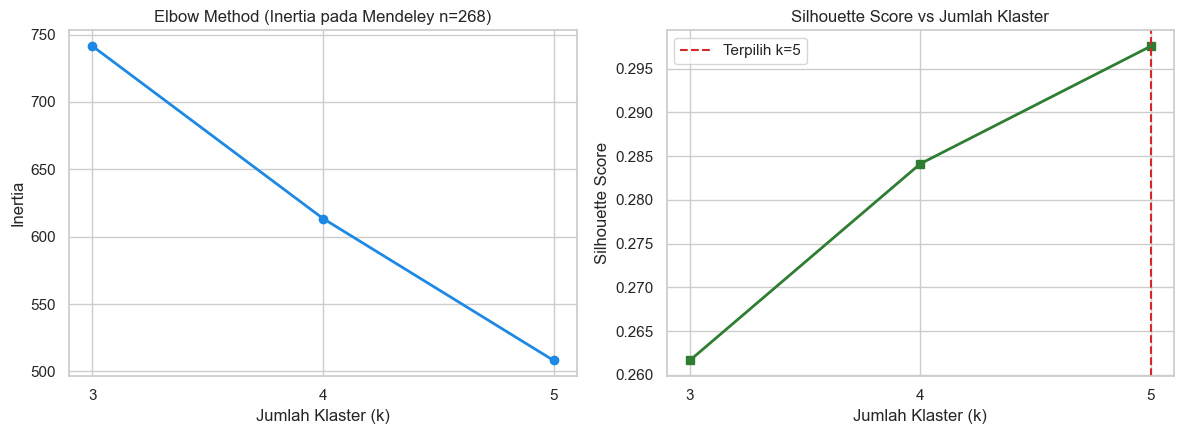


Profil Rata-Rata Sentroid Klaster (Mendeley n=268):


,ash_db,vm_db,fc_db,s_db,hhv_db,n_mendeley,cluster_label
cluster_id,,,,,,,
0,11.096,72.889,15.049,0.136,16.251,68,Cluster 0: Moderate-Ash / Medium-Calorie Agro
1,4.544,71.757,23.724,0.056,19.198,60,Cluster 1: High-Calorie / High-FC Shell & Char...
2,31.758,57.048,11.193,0.548,14.032,12,Cluster 2: High-Ash / Low-Calorie Residue
3,8.308,75.890,15.804,1.514,18.298,5,Cluster 3: Elevated-Sulfur / Rich-Organic
4,2.390,82.670,14.782,0.045,18.876,123,Cluster 4: High-Volatile / Low-Ash Woody & Agro


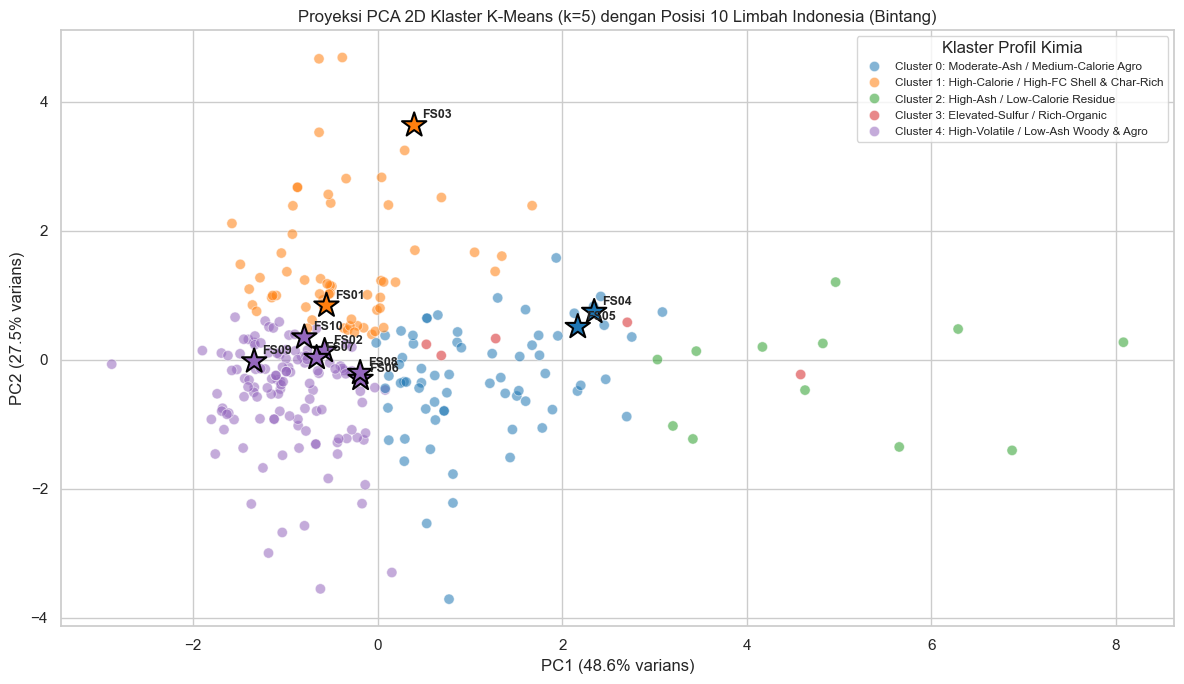

In [4]:
CLUSTER_FEATURES = ["ash_db", "vm_db", "fc_db", "s_db", "hhv_db"]
X_cluster_train = df_mend[CLUSTER_FEATURES].copy()

k_candidates = [3, 4, 5]
cluster_eval = []
pipelines_by_k = {}

for k in k_candidates:
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("kmeans", KMeans(n_clusters=k, random_state=42, n_init=20)),
    ])
    labels_k = pipe.fit_predict(X_cluster_train)
    X_scaled_k = pipe.named_steps["scaler"].transform(X_cluster_train)
    sil = float(silhouette_score(X_scaled_k, labels_k))
    inertia = float(pipe.named_steps["kmeans"].inertia_)
    cluster_eval.append({"k": k, "inertia": inertia, "silhouette_score": sil})
    pipelines_by_k[k] = pipe

cluster_eval_df = pd.DataFrame(cluster_eval)
display(cluster_eval_df.round(4))

# Pilih k dengan Silhouette Score tertinggi di rentang kandidat {3, 4, 5}
best_k_row = cluster_eval_df.sort_values("silhouette_score", ascending=False).iloc[0]
best_k = int(best_k_row["k"])
best_sil = float(best_k_row["silhouette_score"])
best_km_pipe = pipelines_by_k[best_k]

print(f"Jumlah klaster terpilih: k = {best_k} (Silhouette Score = {best_sil:.4f})")

# Plot Elbow & Silhouette
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(cluster_eval_df["k"], cluster_eval_df["inertia"], marker="o", linewidth=2, color="#1E88E5")
axes[0].set_title("Elbow Method (Inertia pada Mendeley n=268)")
axes[0].set_xlabel("Jumlah Klaster (k)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(k_candidates)

axes[1].plot(cluster_eval_df["k"], cluster_eval_df["silhouette_score"], marker="s", linewidth=2, color="#2E7D32")
axes[1].axvline(best_k, color="#D62728", linestyle="--", label=f"Terpilih k={best_k}")
axes[1].set_title("Silhouette Score vs Jumlah Klaster")
axes[1].set_xlabel("Jumlah Klaster (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(k_candidates)
axes[1].legend()

plt.tight_layout()
fig_km_eval = FIGURES_DIR / "03_kmeans_elbow_silhouette.png"
plt.savefig(fig_km_eval, dpi=150, bbox_inches="tight")
plt.show()

# Beri label deskriptif berbasis rata-rata fitur tiap sentroid pada data Mendeley
df_mend_clustered = df_mend.copy()
df_mend_clustered["cluster_id"] = best_km_pipe.predict(X_cluster_train)
centroids_summary = (
    df_mend_clustered.groupby("cluster_id")[CLUSTER_FEATURES]
    .agg(["count", "mean"])
)
centroid_means = df_mend_clustered.groupby("cluster_id")[CLUSTER_FEATURES].mean()

# Beri nama klaster secara objektif berdasarkan profil ash_db, fc_db, s_db, dan hhv_db
cluster_label_map = {}
for cid, row in centroid_means.iterrows():
    if row["ash_db"] >= 15.0 or row["hhv_db"] < 15.5:
        lbl = f"Cluster {cid}: High-Ash / Low-Calorie Residue"
    elif row["s_db"] >= 0.35:
        lbl = f"Cluster {cid}: Elevated-Sulfur / Rich-Organic"
    elif row["fc_db"] >= 20.0 and row["hhv_db"] >= 18.5:
        lbl = f"Cluster {cid}: High-Calorie / High-FC Shell & Char-Rich"
    elif row["vm_db"] >= 76.0 and row["ash_db"] < 6.0:
        lbl = f"Cluster {cid}: High-Volatile / Low-Ash Woody & Agro"
    else:
        lbl = f"Cluster {cid}: Moderate-Ash / Medium-Calorie Agro"
    cluster_label_map[int(cid)] = lbl

# Pastikan nama label unik apabila dua klaster jatuh ke deskripsi serupa
if len(set(cluster_label_map.values())) < len(cluster_label_map):
    cluster_label_map = {int(cid): f"Cluster {cid}: HHV~{centroid_means.loc[cid, 'hhv_db']:.1f} / Ash~{centroid_means.loc[cid, 'ash_db']:.1f}%" for cid in centroid_means.index}

print("\nProfil Rata-Rata Sentroid Klaster (Mendeley n=268):")
centroid_display = centroid_means.copy()
centroid_display["n_mendeley"] = df_mend_clustered.groupby("cluster_id").size()
centroid_display["cluster_label"] = [cluster_label_map[int(c)] for c in centroid_display.index]
display(centroid_display.round(3))

# Proyeksikan 10 profil Indonesia menggunakan predicted_hhv_db
X_phy_cluster = df_val[["ash_db", "vm_db", "fc_db", "s_db", "predicted_hhv_db"]].rename(
    columns={"predicted_hhv_db": "hhv_db"}
)
df_val["cluster_id"] = best_km_pipe.predict(X_phy_cluster)
df_val["cluster_label"] = df_val["cluster_id"].map(cluster_label_map)

# Simpan model K-Means pipeline (StandardScaler + KMeans)
joblib.dump(best_km_pipe, MODELS_DIR / "kmeans_feedstock_profile.joblib")

# Visualisasi PCA 2D: sebaran Mendeley + proyeksi 10 profil Indonesia
pca = PCA(n_components=2, random_state=42)
X_mend_pca = pca.fit_transform(best_km_pipe.named_steps["scaler"].transform(X_cluster_train))
X_phy_pca = pca.transform(best_km_pipe.named_steps["scaler"].transform(X_phy_cluster))

df_pca_m = pd.DataFrame({
    "PC1": X_mend_pca[:, 0],
    "PC2": X_mend_pca[:, 1],
    "cluster_label": df_mend_clustered["cluster_id"].map(cluster_label_map),
})
df_pca_p = pd.DataFrame({
    "PC1": X_phy_pca[:, 0],
    "PC2": X_phy_pca[:, 1],
    "feedstock_id": df_val["feedstock_id"],
    "feedstock_name": df_val["feedstock_name"],
    "cluster_label": df_val["cluster_label"],
})

fig, ax = plt.subplots(figsize=(12, 7))
hue_order = [cluster_label_map[i] for i in sorted(cluster_label_map.keys())]
cluster_palette = dict(zip(hue_order, sns.color_palette("tab10", n_colors=len(hue_order))))
sns.scatterplot(
    data=df_pca_m,
    x="PC1",
    y="PC2",
    hue="cluster_label",
    hue_order=hue_order,
    palette=cluster_palette,
    alpha=0.55,
    s=55,
    ax=ax,
)
sns.scatterplot(
    data=df_pca_p,
    x="PC1",
    y="PC2",
    hue="cluster_label",
    hue_order=hue_order,
    palette=cluster_palette,
    marker="*",
    s=340,
    edgecolor="black",
    legend=False,
    ax=ax,
)
for _, r in df_pca_p.iterrows():
    ax.annotate(
        f"{r['feedstock_id']}",
        (r["PC1"], r["PC2"]),
        textcoords="offset points",
        xytext=(6, 5),
        fontsize=9,
        fontweight="bold",
    )

var_exp = pca.explained_variance_ratio_ * 100.0
ax.set_title(f"Proyeksi PCA 2D Klaster K-Means (k={best_k}) dengan Posisi 10 Limbah Indonesia (Bintang)")
ax.set_xlabel(f"PC1 ({var_exp[0]:.1f}% varians)")
ax.set_ylabel(f"PC2 ({var_exp[1]:.1f}% varians)")
ax.legend(title="Klaster Profil Kimia", loc="best", fontsize=8.5)

plt.tight_layout()
fig_pca_path = FIGURES_DIR / "03_kmeans_pca_projection.png"
plt.savefig(fig_pca_path, dpi=150, bbox_inches="tight")
plt.show()

**Interpretasi klasterisasi K-Means:**
- Model *K-Means* dilatih sepenuhnya pada 268 sampel Mendeley sehingga posisi klaster merepresentasikan spektrum sifat kimia biomassa global tanpa bias dari 10 titik uji.
- Pada peta PCA 2D, tanda bintang (`FS01`-`FS10`) memperlihatkan kedekatan profil kimia limbah Indonesia terhadap klaster global: bahan baku berkadar abu tinggi (`FS04` sekam padi dan `FS05` jerami padi) mengelompok terpisah dari bahan baku berkadar abu rendah dan energi tinggi (`FS01` PKS, `FS09` serbuk gergaji, `FS10` *wood chips*).

## 5. Ekspor `phyllis2_10_validated.csv`, Pembaruan `metrics_summary.json`, & Verifikasi Akhir DoD

**Langkah yang dikerjakan:** Menyimpan tabel final `data/processed/phyllis2_10_validated.csv`, memperbarui `outputs/metrics_summary.json` dengan hasil validasi eksternal dan *Silhouette Score*, serta menjalankan verifikasi otomatis seluruh gerbang *Definition of Done* dan *Success Criteria* Tahap 2B.

In [5]:
# Ekspor tabel profil kandidat bahan baku tervalidasi siap pakai untuk tahap Data Warehouse
validated_out_path = PROCESSED_DIR / "phyllis2_10_validated.csv"
df_val.to_csv(validated_out_path, index=False)

# Perbarui outputs/metrics_summary.json
metrics_path = OUTPUTS_DIR / "metrics_summary.json"
with open(metrics_path, "r", encoding="utf-8") as f:
    metrics_payload = json.load(f)

metrics_payload["external_validation_phyllis2"] = {
    "summary_metrics": ext_metrics_rows,
    "per_feedstock": df_val[[
        "feedstock_id", "feedstock_name", "proximate_source",
        "actual_hhv_db", "predicted_hhv_prox_db", "err_prox_pct",
        "predicted_hhv_full_db", "err_full_pct",
        "effective_lhv_lab_mj_kg", "actual_lhv_ar",
        "effective_lhv_field_mj_kg", "high_moisture_flag",
        "boiler_status", "alkali_chlorine_flag", "screening_recommendation",
        "cluster_id", "cluster_label",
    ]].to_dict(orient="records"),
}
metrics_payload["kmeans_clustering"] = {
    "features": CLUSTER_FEATURES,
    "trained_on": "data/processed/mendeley_clean.csv (n=268)",
    "candidates": cluster_eval,
    "selected_k": best_k,
    "selected_silhouette_score": best_sil,
    "cluster_labels": cluster_label_map,
}

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics_payload, f, indent=2)

# Verifikasi otomatis gerbang DoD & Success Criteria Tahap 2B
required_nb03_files = [
    validated_out_path,
    MODELS_DIR / "kmeans_feedstock_profile.joblib",
    metrics_path,
    FIGURES_DIR / "03_external_validation_actual_vs_pred.png",
    FIGURES_DIR / "03_lhv_and_boiler_screening_matrix.png",
    FIGURES_DIR / "03_kmeans_elbow_silhouette.png",
    FIGURES_DIR / "03_kmeans_pca_projection.png",
]
for p in required_nb03_files:
    assert p.exists() and p.stat().st_size > 0, f"Artefak Tahap 2B kosong atau hilang: {p}"

required_cols_val = [
    "predicted_hhv_prox_db", "predicted_hhv_full_db", "predicted_hhv_db",
    "effective_lhv_lab_mj_kg", "effective_lhv_field_mj_kg", "high_moisture_flag",
    "boiler_status", "alkali_chlorine_flag", "screening_recommendation",
    "cluster_id", "cluster_label",
]
assert all(c in df_val.columns for c in required_cols_val)
assert df_val[required_cols_val].isna().sum().sum() == 0

# Cek Success Criteria: MAPE eksternal <= 10% untuk Skenario B (10 profil dan 9 profil murni)
mape_10_b = ext_metrics_df.loc[
    (ext_metrics_df["Himpunan Uji"] == "10 Profil Lengkap (FS01-FS10)")
    & (ext_metrics_df["Skenario"] == "Skenario B (Proximate + Ultimate)"),
    "MAPE_pct",
].values[0]
mape_9_b = ext_metrics_df.loc[
    (ext_metrics_df["Himpunan Uji"] == "9 Profil Murni (FS02-FS10)")
    & (ext_metrics_df["Skenario"] == "Skenario B (Proximate + Ultimate)"),
    "MAPE_pct",
].values[0]
assert mape_10_b <= 10.0, f"MAPE eksternal 10 profil ({mape_10_b:.2f}%) > 10%"
assert mape_9_b <= 10.0, f"MAPE eksternal 9 profil murni ({mape_9_b:.2f}%) > 10%"

# Cek konsistensi fisika LHV & aturan screening boiler
assert (df_val["effective_lhv_field_mj_kg"] < df_val["predicted_hhv_db"]).all()
assert set(df_val.loc[df_val["high_moisture_flag"], "feedstock_id"]) == {"FS02", "FS06"}
assert set(df_val.loc[df_val["boiler_status"] == "Not Eligible", "feedstock_id"]) == {"FS04", "FS05"}
assert df_val.loc[df_val["feedstock_id"] == "FS01", "alkali_chlorine_flag"].values[0] == "Data Unavailable"
assert set(df_val.loc[df_val["alkali_chlorine_flag"] == "Low Risk", "feedstock_id"]) == {"FS09", "FS10"}
assert best_sil > 0.25, f"Silhouette Score ({best_sil:.4f}) <= 0.25"

print("SELURUH GERBANG VERIFIKASI TAHAP 2B LULUS:")
print(f"  - Validasi Eksternal Skenario B (10 Profil): MAPE = {mape_10_b:.2f}%")
print(f"  - Validasi Eksternal Skenario B (9 Profil Murni): MAPE = {mape_9_b:.2f}%")
print(f"  - Klasterisasi K-Means: k = {best_k}, Silhouette Score = {best_sil:.4f}")
print(f"  - Output akhir tersimpan di: {validated_out_path}")

SELURUH GERBANG VERIFIKASI TAHAP 2B LULUS:
  - Validasi Eksternal Skenario B (10 Profil): MAPE = 3.40%
  - Validasi Eksternal Skenario B (9 Profil Murni): MAPE = 3.27%
  - Klasterisasi K-Means: k = 5, Silhouette Score = 0.2976
  - Output akhir tersimpan di: D:\UPN VY\Semester 5\BI\Tugas\projectkb\data\processed\phyllis2_10_validated.csv
